<a href="https://colab.research.google.com/github/Prithivi-r/DS-SAT2/blob/main/Cyber_Traffic_Insight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_file = next(iter(uploaded))

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall("/content/cyber_traffic")

print("Files extracted successfully:")
print(os.listdir("/content/cyber_traffic"))


Saving Cyber_Traffic_Insight_CSV_Files.zip to Cyber_Traffic_Insight_CSV_Files.zip
Files extracted successfully:
['calendar.csv', 'flows.csv', 'sessions.csv', 'README.txt', 'labels.csv', 'hosts.csv']


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

data_path = "/content/cyber_traffic"

flows = pd.read_csv(f"{data_path}/flows.csv")
hosts = pd.read_csv(f"{data_path}/hosts.csv")
sessions = pd.read_csv(f"{data_path}/sessions.csv")
labels = pd.read_csv(f"{data_path}/labels.csv")
calendar = pd.read_csv(f"{data_path}/calendar.csv")

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [ ]:

datasets = {
    "flows": flows,
    "hosts": hosts,
    "sessions": sessions,
    "labels": labels,
    "calendar": calendar
}

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print("Shape:", df.shape)
    display(df.head())



FLOWS
Shape: (1205, 6)


,flow_id,timestamp,protocol,duration,bytes,packets
0,F00000,2026-09-01 00:00:00,UDP,NaN,3269,3
1,F00001,2026-09-01 00:05:00,TCP,9.40,2937,2
2,F00002,2026-09-01 00:10:00,TCP,1.62,2866,3
3,F00003,2026-09-01 00:15:00,TCP,8.04,1683,4
4,F00004,2026-09-01 00:20:00,ICMP,11.29,1718,1



HOSTS
Shape: (6, 2)


,host_group,network_zone
0,Student_Lab,Internal
1,Admin_Network,Internal
2,Server_Farm,DMZ
3,Guest_WiFi,External
4,Research_Lab,Internal



SESSIONS
Shape: (1200, 5)


,flow_id,host_group,source_zone,destination_zone,port_category
0,F00000,Server_Farm,Internal,External,DNS
1,F00001,Guest_WiFi,Internal,DMZ,Remote_Access
2,F00002,Student_Lab,Internal,External,Database
3,F00003,Guest_WiFi,Internal,DMZ,Other
4,F00004,Admin_Network,DMZ,External,Remote_Access



LABELS
Shape: (1200, 2)


,flow_id,label
0,F00000,normal
1,F00001,normal
2,F00002,maintenance_activity
3,F00003,normal
4,F00004,normal



CALENDAR
Shape: (1200, 4)


,timestamp,hour,weekday,maintenance_window
0,2026-09-01 00:00:00,0,Tuesday,No
1,2026-09-01 00:05:00,0,Tuesday,No
2,2026-09-01 00:10:00,0,Tuesday,No
3,2026-09-01 00:15:00,0,Tuesday,No
4,2026-09-01 00:20:00,0,Tuesday,No


In [ ]:

for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")
    print("Data types:")
    print(df.dtypes)
    print("\nMissing values:")
    print(df.isnull().sum())
    print("\nDuplicate rows:", df.duplicated().sum())



--- FLOWS ---
Data types:
flow_id       object
timestamp     object
protocol      object
duration     float64
bytes          int64
packets        int64
dtype: object

Missing values:
flow_id       0
timestamp     0
protocol     44
duration     13
bytes         0
packets       0
dtype: int64

Duplicate rows: 5

--- HOSTS ---
Data types:
host_group      object
network_zone    object
dtype: object

Missing values:
host_group      0
network_zone    0
dtype: int64

Duplicate rows: 0

--- SESSIONS ---
Data types:
flow_id             object
host_group          object
source_zone         object
destination_zone    object
port_category       object
dtype: object

Missing values:
flow_id             0
host_group          0
source_zone         0
destination_zone    0
port_category       0
dtype: int64

Duplicate rows: 0

--- LABELS ---
Data types:
flow_id    object
label      object
dtype: object

Missing values:
flow_id    0
label      2
dtype: int64

Duplicate rows: 0

--- CALENDAR ---
Data ty

In [ ]:

print("Duplicate flow IDs:", flows["flow_id"].duplicated().sum())

print("\nProtocol values:")
print(flows["protocol"].value_counts(dropna=False))

print("\nLabel values:")
print(labels["label"].value_counts(dropna=False))

print("\nByte statistics:")
display(flows["bytes"].describe())


Duplicate flow IDs: 5

Protocol values:
protocol
TCP     667
UDP     375
ICMP    119
NaN      44
Name: count, dtype: int64

Label values:
label
normal                  910
unusual_volume          119
repeated_alert           87
maintenance_activity     79
NaN                       2
Normal                    1
NORMAL                    1
 unusual_volume           1
Name: count, dtype: int64

Byte statistics:


,bytes
count,1.205000e+03
mean,1.208590e+04
std,7.632572e+04
min,8.200000e+01
25%,1.720000e+03
50%,3.745000e+03
75%,8.272000e+03
max,2.152322e+06


In [ ]:

# Keep the first record for each flow ID
flows_clean = flows.drop_duplicates(
    subset="flow_id", keep="first"
).copy()

# Standardize protocols
flows_clean["protocol"] = (
    flows_clean["protocol"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .str.upper()
)

# Convert numeric columns safely
flows_clean["duration"] = pd.to_numeric(
    flows_clean["duration"], errors="coerce"
)
flows_clean["bytes"] = pd.to_numeric(
    flows_clean["bytes"], errors="coerce"
)
flows_clean["packets"] = pd.to_numeric(
    flows_clean["packets"], errors="coerce"
)

# Fill missing numeric values with their medians
for col in ["duration", "bytes", "packets"]:
    flows_clean[col] = flows_clean[col].fillna(
        flows_clean[col].median()
    )

# Standardize labels
labels_clean = labels.copy()
labels_clean["label"] = (
    labels_clean["label"]
    .fillna("unknown")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Remove duplicate label records, if any
labels_clean = labels_clean.drop_duplicates(
    subset="flow_id", keep="first"
)

# Remove duplicate session records by flow ID
sessions_clean = sessions.drop_duplicates(
    subset="flow_id", keep="first"
).copy()

# Clean host names
hosts_clean = hosts.drop_duplicates(
    subset="host_group", keep="first"
).copy()

print("Data cleaning completed.")
print("Flows:", flows_clean.shape)
print("Sessions:", sessions_clean.shape)
print("Labels:", labels_clean.shape)


Data cleaning completed.
Flows: (1200, 6)
Sessions: (1200, 5)
Labels: (1200, 2)


In [ ]:

flows_clean["timestamp"] = pd.to_datetime(
    flows_clean["timestamp"], errors="coerce"
)
calendar_clean = calendar.copy()
calendar_clean["timestamp"] = pd.to_datetime(
    calendar_clean["timestamp"], errors="coerce"
)

# Keep only one calendar record per timestamp
calendar_clean = calendar_clean.drop_duplicates(
    subset="timestamp"
)

# Merge the datasets
df = flows_clean.merge(
    sessions_clean,
    on="flow_id",
    how="left",
    validate="one_to_one"
)

df = df.merge(
    labels_clean,
    on="flow_id",
    how="left",
    validate="one_to_one"
)

df = df.merge(
    hosts_clean,
    on="host_group",
    how="left",
    validate="many_to_one"
)

df = df.merge(
    calendar_clean,
    on="timestamp",
    how="left",
    validate="many_to_one",
    suffixes=("", "_calendar")
)

print("Combined dataset shape:", df.shape)
display(df.head())


Combined dataset shape: (1200, 15)


,flow_id,timestamp,protocol,duration,bytes,packets,host_group,source_zone,destination_zone,port_category,label,network_zone,hour,weekday,maintenance_window
0,F00000,2026-09-01 00:00:00,UDP,6.16,3269,3,Server_Farm,Internal,External,DNS,normal,DMZ,0,Tuesday,No
1,F00001,2026-09-01 00:05:00,TCP,9.40,2937,2,Guest_WiFi,Internal,DMZ,Remote_Access,normal,External,0,Tuesday,No
2,F00002,2026-09-01 00:10:00,TCP,1.62,2866,3,Student_Lab,Internal,External,Database,maintenance_activity,Internal,0,Tuesday,No
3,F00003,2026-09-01 00:15:00,TCP,8.04,1683,4,Guest_WiFi,Internal,DMZ,Other,normal,External,0,Tuesday,No
4,F00004,2026-09-01 00:20:00,ICMP,11.29,1718,1,Admin_Network,DMZ,External,Remote_Access,normal,Internal,0,Tuesday,No


In [ ]:

print("Columns:")
print(df.columns.tolist())

print("\nMissing values after merging:")
print(df.isnull().sum())

print("\nUnmatched host groups:")
print(df.loc[df["network_zone"].isna(), "host_group"]
      .dropna().unique())


Columns:
['flow_id', 'timestamp', 'protocol', 'duration', 'bytes', 'packets', 'host_group', 'source_zone', 'destination_zone', 'port_category', 'label', 'network_zone', 'hour', 'weekday', 'maintenance_window']

Missing values after merging:
flow_id               0
timestamp             0
protocol              0
duration              0
bytes                 0
packets               0
host_group            0
source_zone           0
destination_zone      0
port_category         0
label                 0
network_zone          0
hour                  0
weekday               0
maintenance_window    0
dtype: int64

Unmatched host groups:
[]


protocol
TCP        502
UDP        281
ICMP        94
UNKNOWN     35
Name: count, dtype: int64


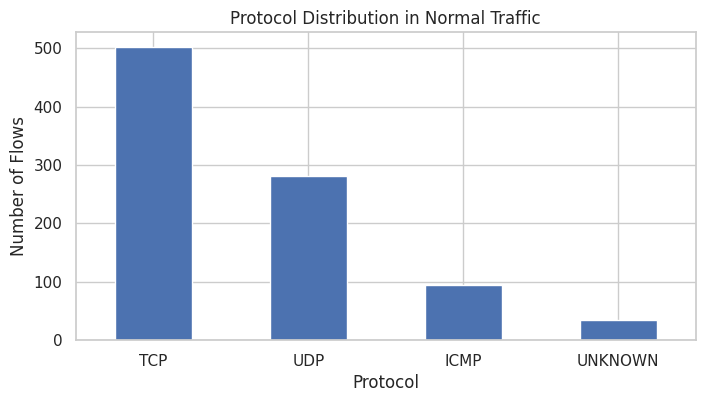

In [ ]:

normal_traffic = df[
    df["label"].astype(str).str.strip().str.lower() == "normal"
]

print(normal_traffic["protocol"].value_counts())

normal_traffic["protocol"].value_counts().plot(
    kind="bar", figsize=(8, 4)
)
plt.title("Protocol Distribution in Normal Traffic")
plt.xlabel("Protocol")
plt.ylabel("Number of Flows")
plt.xticks(rotation=0)
plt.show()


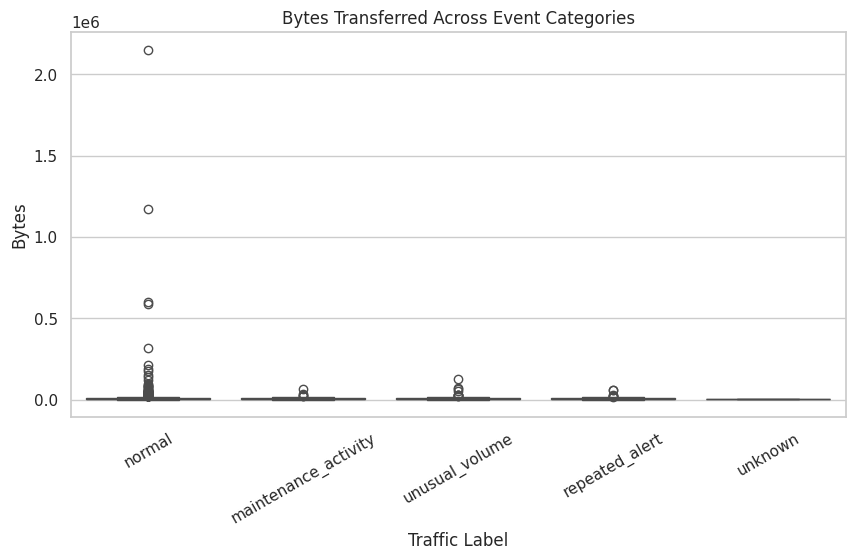

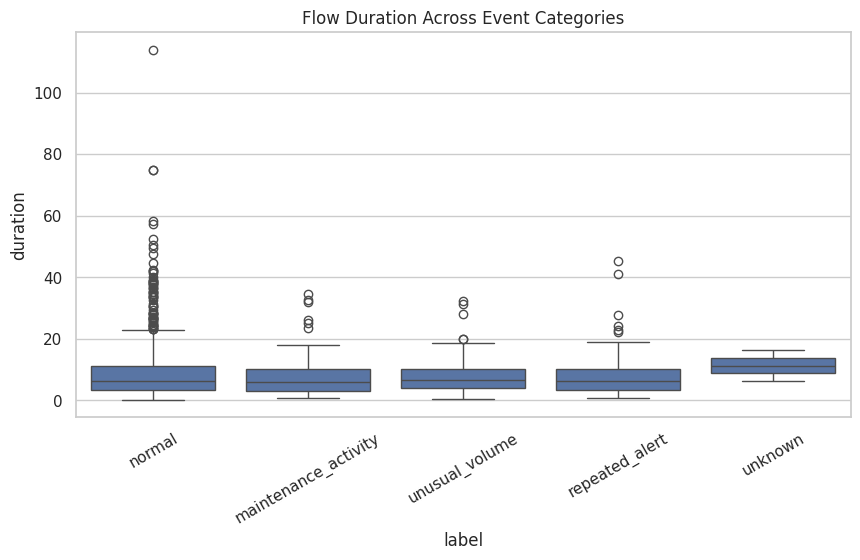

In [ ]:

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="label", y="bytes")
plt.title("Bytes Transferred Across Event Categories")
plt.xlabel("Traffic Label")
plt.ylabel("Bytes")
plt.xticks(rotation=30)
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="label", y="duration")
plt.title("Flow Duration Across Event Categories")
plt.xticks(rotation=30)
plt.show()


,hour,total_flows,total_bytes
0,0,60,392042
1,1,60,532276
2,2,60,594869
3,3,60,569747
4,4,48,193176
5,5,48,269061
6,6,48,355332
7,7,48,3065483
8,8,48,429507
9,9,48,400869


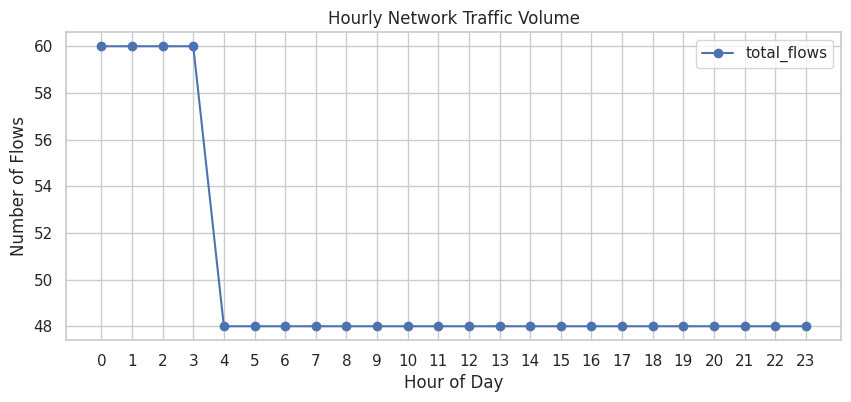

In [ ]:

df["hour"] = df["timestamp"].dt.hour

hourly_traffic = df.groupby("hour").agg(
    total_flows=("flow_id", "count"),
    total_bytes=("bytes", "sum")
).reset_index()

display(hourly_traffic)

hourly_traffic.plot(
    x="hour", y="total_flows",
    kind="line", marker="o", figsize=(10, 4)
)
plt.title("Hourly Network Traffic Volume")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Flows")
plt.xticks(range(24))
plt.show()


,source_zone,total_flows,average_bytes,average_packets,average_duration
0,DMZ,252,13499.642857,14.900794,8.413492
1,External,179,13906.502793,16.061453,10.549553
2,Internal,769,11241.326398,11.304291,8.699909


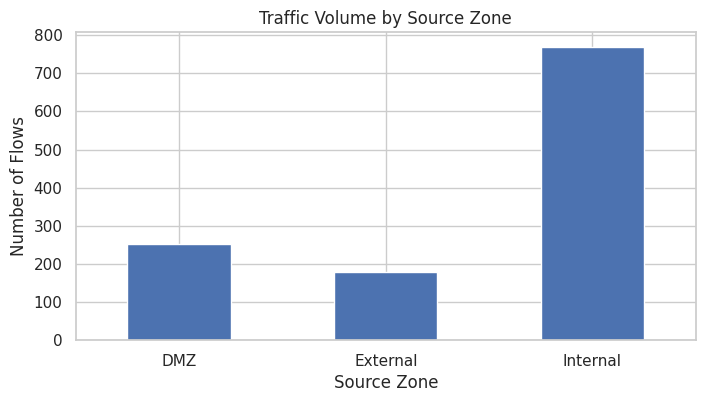

In [ ]:

zone_comparison = df.groupby("source_zone").agg(
    total_flows=("flow_id", "count"),
    average_bytes=("bytes", "mean"),
    average_packets=("packets", "mean"),
    average_duration=("duration", "mean")
).reset_index()

display(zone_comparison)

zone_comparison.plot(
    x="source_zone", y="total_flows",
    kind="bar", legend=False, figsize=(8, 4)
)
plt.title("Traffic Volume by Source Zone")
plt.xlabel("Source Zone")
plt.ylabel("Number of Flows")
plt.xticks(rotation=0)
plt.show()


,port_category,total_flows,average_bytes,total_bytes
5,Web,474,10106.141350,4790311
0,DNS,208,9096.807692,1892136
3,Other,175,9863.445714,1726103
2,Email,127,22671.551181,2879287
1,Database,123,7769.333333,955628
4,Remote_Access,93,24648.268817,2292289


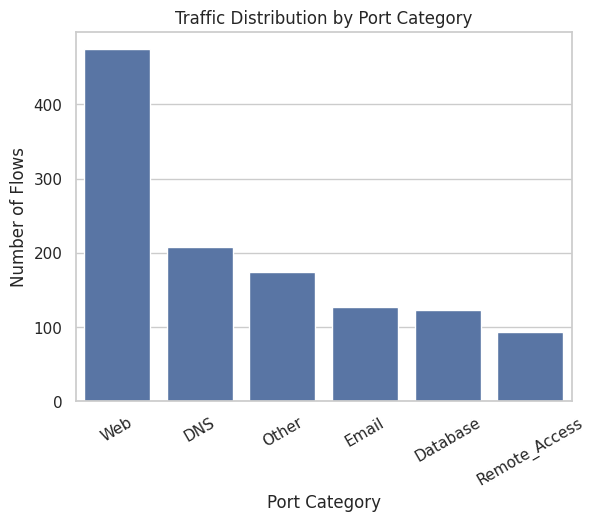

In [ ]:

port_analysis = df.groupby("port_category").agg(
    total_flows=("flow_id", "count"),
    average_bytes=("bytes", "mean"),
    total_bytes=("bytes", "sum")
).reset_index().sort_values("total_flows", ascending=False)

display(port_analysis)

sns.barplot(data=port_analysis, x="port_category", y="total_flows")
plt.title("Traffic Distribution by Port Category")
plt.xlabel("Port Category")
plt.ylabel("Number of Flows")
plt.xticks(rotation=30)
plt.show()


,host_group,alert_count,total_bytes
3,Server_Farm,49,305752
4,Student_Lab,45,300536
2,Research_Lab,42,490311
0,Admin_Network,40,248310
1,Guest_WiFi,31,207507


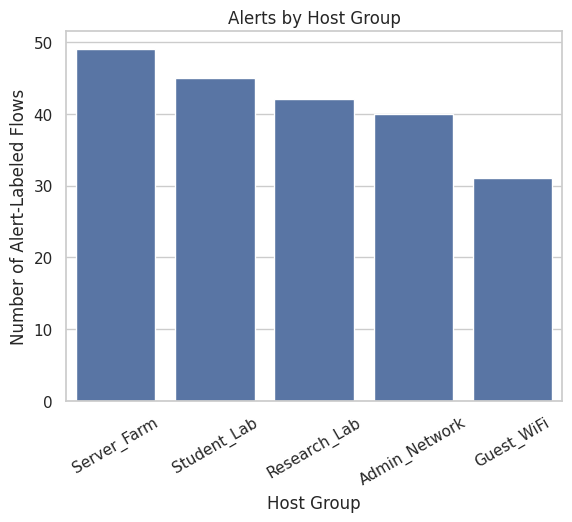

In [ ]:

alert_labels = ["unusual_volume", "repeated_alert"]

alerts = df[
    df["label"].astype(str).str.strip().str.lower()
    .isin(alert_labels)
]

host_alerts = alerts.groupby("host_group").agg(
    alert_count=("flow_id", "count"),
    total_bytes=("bytes", "sum")
).reset_index().sort_values("alert_count", ascending=False)

display(host_alerts)

sns.barplot(data=host_alerts, x="host_group", y="alert_count")
plt.title("Alerts by Host Group")
plt.xlabel("Host Group")
plt.ylabel("Number of Alert-Labeled Flows")
plt.xticks(rotation=30)
plt.show()


In [ ]:

# Create new features
df["bytes_per_packet"] = np.where(
    df["packets"] > 0,
    df["bytes"] / df["packets"],
    np.nan
)

df["log_bytes"] = np.log1p(df["bytes"])

df["is_internal_to_external"] = (
    (df["source_zone"] == "Internal") &
    (df["destination_zone"] == "External")
).astype(int)

# Flag the top 1% of byte counts for investigation
byte_threshold = df["bytes"].quantile(0.99)

df["high_byte_flag"] = (
    df["bytes"] > byte_threshold
).astype(int)

# Flag records with alert-related labels
df["alert_flag"] = df["label"].isin(
    ["unusual_volume", "repeated_alert"]
).astype(int)

print("Feature engineering completed!")
display(df.head())


Feature engineering completed!


,flow_id,timestamp,protocol,duration,bytes,packets,host_group,source_zone,destination_zone,port_category,label,network_zone,hour,weekday,maintenance_window,bytes_per_packet,log_bytes,is_internal_to_external,high_byte_flag,alert_flag
0,F00000,2026-09-01 00:00:00,UDP,6.16,3269,3,Server_Farm,Internal,External,DNS,normal,DMZ,0,Tuesday,No,1089.666667,8.092545,1,0,0
1,F00001,2026-09-01 00:05:00,TCP,9.40,2937,2,Guest_WiFi,Internal,DMZ,Remote_Access,normal,External,0,Tuesday,No,1468.500000,7.985484,0,0,0
2,F00002,2026-09-01 00:10:00,TCP,1.62,2866,3,Student_Lab,Internal,External,Database,maintenance_activity,Internal,0,Tuesday,No,955.333333,7.961021,1,0,0
3,F00003,2026-09-01 00:15:00,TCP,8.04,1683,4,Guest_WiFi,Internal,DMZ,Other,normal,External,0,Tuesday,No,420.750000,7.428927,0,0,0
4,F00004,2026-09-01 00:20:00,ICMP,11.29,1718,1,Admin_Network,DMZ,External,Remote_Access,normal,Internal,0,Tuesday,No,1718.000000,7.449498,0,0,0


In [ ]:

# Create new features
df["bytes_per_packet"] = np.where(
    df["packets"] > 0,
    df["bytes"] / df["packets"],
    np.nan
)

df["log_bytes"] = np.log1p(df["bytes"])

df["is_internal_to_external"] = (
    (df["source_zone"] == "Internal") &
    (df["destination_zone"] == "External")
).astype(int)

# Flag the top 1% of byte counts for investigation
byte_threshold = df["bytes"].quantile(0.99)

df["high_byte_flag"] = (
    df["bytes"] > byte_threshold
).astype(int)

# Flag records with alert-related labels
df["alert_flag"] = df["label"].isin(
    ["unusual_volume", "repeated_alert"]
).astype(int)

print("Feature engineering completed!")
display(df.head())


Feature engineering completed!


,flow_id,timestamp,protocol,duration,bytes,packets,host_group,source_zone,destination_zone,port_category,label,network_zone,hour,weekday,maintenance_window,bytes_per_packet,log_bytes,is_internal_to_external,high_byte_flag,alert_flag
0,F00000,2026-09-01 00:00:00,UDP,6.16,3269,3,Server_Farm,Internal,External,DNS,normal,DMZ,0,Tuesday,No,1089.666667,8.092545,1,0,0
1,F00001,2026-09-01 00:05:00,TCP,9.40,2937,2,Guest_WiFi,Internal,DMZ,Remote_Access,normal,External,0,Tuesday,No,1468.500000,7.985484,0,0,0
2,F00002,2026-09-01 00:10:00,TCP,1.62,2866,3,Student_Lab,Internal,External,Database,maintenance_activity,Internal,0,Tuesday,No,955.333333,7.961021,1,0,0
3,F00003,2026-09-01 00:15:00,TCP,8.04,1683,4,Guest_WiFi,Internal,DMZ,Other,normal,External,0,Tuesday,No,420.750000,7.428927,0,0,0
4,F00004,2026-09-01 00:20:00,ICMP,11.29,1718,1,Admin_Network,DMZ,External,Remote_Access,normal,Internal,0,Tuesday,No,1718.000000,7.449498,0,0,0


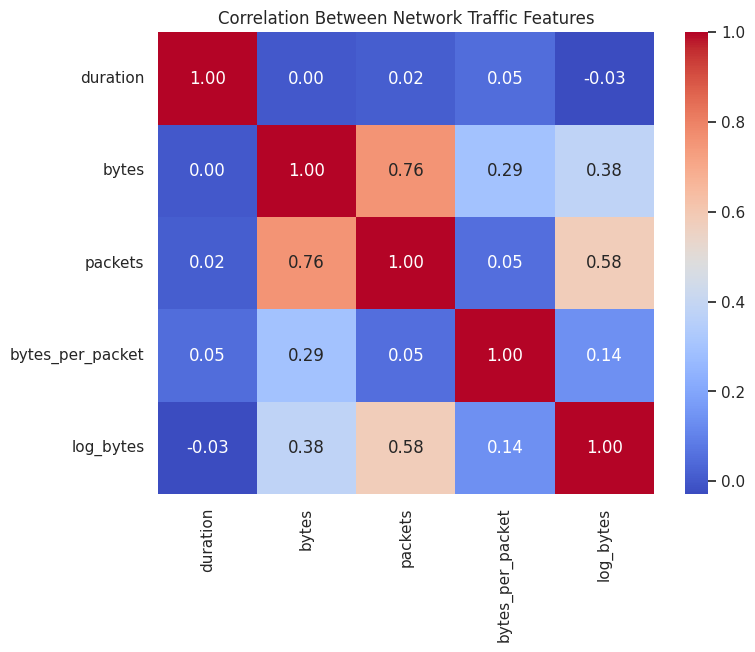

In [ ]:

numeric_columns = [
    "duration", "bytes", "packets",
    "bytes_per_packet", "log_bytes"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Network Traffic Features")
plt.show()


In [ ]:

selected_columns = [
    "flow_id", "timestamp", "protocol",
    "duration", "bytes", "packets",
    "bytes_per_packet", "log_bytes",
    "high_byte_flag", "source_zone",
    "destination_zone", "port_category",
    "host_group", "network_zone", "hour",
    "weekday", "maintenance_window",
    "label", "alert_flag"
]

# Keep only columns that exist in df
selected_columns = [
    col for col in selected_columns if col in df.columns
]

selected_df = df[selected_columns].copy()

print("Feature selection completed!")
print(selected_df.shape)
display(selected_df.head())


Feature selection completed!
(1200, 19)


,flow_id,timestamp,protocol,duration,bytes,packets,bytes_per_packet,log_bytes,high_byte_flag,source_zone,destination_zone,port_category,host_group,network_zone,hour,weekday,maintenance_window,label,alert_flag
0,F00000,2026-09-01 00:00:00,UDP,6.16,3269,3,1089.666667,8.092545,0,Internal,External,DNS,Server_Farm,DMZ,0,Tuesday,No,normal,0
1,F00001,2026-09-01 00:05:00,TCP,9.40,2937,2,1468.500000,7.985484,0,Internal,DMZ,Remote_Access,Guest_WiFi,External,0,Tuesday,No,normal,0
2,F00002,2026-09-01 00:10:00,TCP,1.62,2866,3,955.333333,7.961021,0,Internal,External,Database,Student_Lab,Internal,0,Tuesday,No,maintenance_activity,0
3,F00003,2026-09-01 00:15:00,TCP,8.04,1683,4,420.750000,7.428927,0,Internal,DMZ,Other,Guest_WiFi,External,0,Tuesday,No,normal,0
4,F00004,2026-09-01 00:20:00,ICMP,11.29,1718,1,1718.000000,7.449498,0,DMZ,External,Remote_Access,Admin_Network,Internal,0,Tuesday,No,normal,0


In [ ]:

output_path = "/content/cleaned_cyber_traffic.csv"

selected_df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")

from google.colab import files
files.download(output_path)


Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>